# 20 · Graph Neural Networks (GNNs)

Much data is a **network**: people and friendships, papers and citations, atoms and bonds, users and the products they buy, roads and junctions. The connections carry information — your friends say something about you; a molecule's behaviour depends on how its atoms are bonded. **Graph neural networks** learn from both the features of each node *and* the structure around it.

**What you'll learn**
1. Graph basics: nodes, edges, adjacency matrices, degree; classic graph features (PageRank, clustering)
2. A non-neural baseline: **label propagation**
3. **Message passing** — the one idea behind all GNNs — 🐍 pure Python → 🔢 NumPy matrix form → 📦 PyTorch
4. A **graph convolutional network (GCN)** from scratch, for semi-supervised node classification with very few labels
5. When GNNs help (**homophily**) and when they hurt (**heterophily**); **over-smoothing** in deep GNNs
6. **Link prediction** (e.g. friend or product recommendation) and **graph classification** (e.g. molecules)
7. The GNN family: GraphSAGE, GAT, GIN, and where GNNs are used

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import math, random, time
import torch
from torch import nn
import torch.nn.functional as F
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); torch.manual_seed(0); random.seed(0)

## 1. Graph basics

A **graph** G = (V, E): a set of **nodes** (vertices) and **edges** connecting pairs of them. Edges can be directed or undirected, weighted or not; nodes and edges can have features.

The **adjacency matrix** A (n × n): $A_{ij} = 1$ if nodes i and j are connected. A node's **degree** = its number of neighbours = row sum of A. Real graphs are **sparse** (most entries 0), so libraries store edge lists instead.

**Zachary's karate club** (1977) — a classic: 34 members of a club, edges = friendships outside the club. The club later split in two after a dispute; can the friendship structure predict who joined which side?

34 nodes, 78 edges, density 0.14
adjacency matrix (first 8 rows/cols):
 [[0 1 1 1 1 1 1 1]
 [1 0 1 1 0 0 0 1]
 [1 1 0 1 0 0 0 1]
 [1 1 1 0 0 0 0 1]
 [1 0 0 0 0 0 1 0]
 [1 0 0 0 0 0 1 0]
 [1 0 0 0 1 1 0 0]
 [1 1 1 1 0 0 0 0]]
degrees of the first 8 nodes: [16  9 10  6  3  4  4  4]


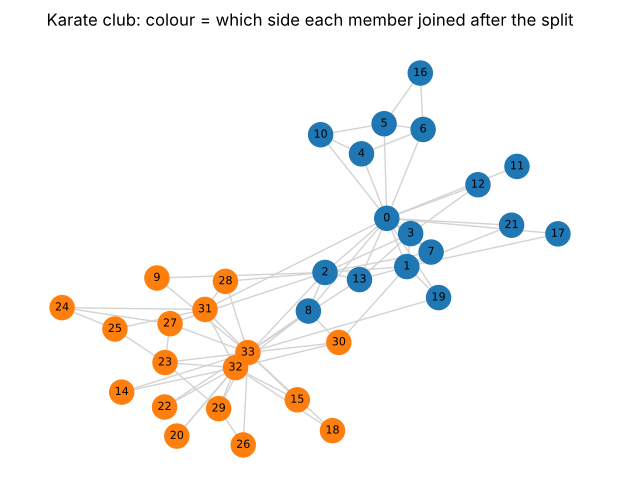

In [2]:
G = nx.karate_club_graph()
A = nx.to_numpy_array(G, weight=None)          # ignore the edge weights networkx stores; 1 = friends
club = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in G.nodes])
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, density {nx.density(G):.2f}")
print("adjacency matrix (first 8 rows/cols):\n", A[:8, :8].astype(int))
print("degrees of the first 8 nodes:", A.sum(1)[:8].astype(int))

pos = nx.spring_layout(G, seed=3)
plt.figure(figsize=(6, 4.5))
nx.draw(G, pos, node_color=["tab:blue" if c == 0 else "tab:orange" for c in club], with_labels=True, node_size=300, font_size=8, edge_color="lightgray")
plt.title("Karate club: colour = which side each member joined after the split"); plt.show()

### Classic graph features
Before GNNs, people computed hand-made node features and fed them to an ordinary model:
- **Degree** — how connected.
- **PageRank** — importance: being linked from important nodes (the eigenvector from notebook 14).
- **Clustering coefficient** — how many of my friends are friends with each other.
- **Shortest-path distance** to key nodes.

In [3]:
feats = {"degree": dict(G.degree()), "PageRank": nx.pagerank(G), "clustering": nx.clustering(G)}
top = sorted(G.nodes, key=lambda n: -feats["PageRank"][n])[:5]
for n in top:
    print(f"node {n:2d}: degree {feats['degree'][n]:2d}, PageRank {feats['PageRank'][n]:.3f}, clustering {feats['clustering'][n]:.2f}")
print("→ nodes 33 and 0 are the two leaders (the instructor and the administrator)")

node 33: degree 17, PageRank 0.097, clustering 0.11
node  0: degree 16, PageRank 0.089, clustering 0.15
node 32: degree 12, PageRank 0.076, clustering 0.20
node  2: degree 10, PageRank 0.063, clustering 0.24
node  1: degree  9, PageRank 0.057, clustering 0.33
→ nodes 33 and 0 are the two leaders (the instructor and the administrator)


## 2. A baseline: label propagation

**Semi-supervised** setting: we know the side of only a few members (say the two leaders) and want to predict everyone else. **Label propagation**: each unlabelled node repeatedly takes the average label distribution of its neighbours, while known labels stay clamped. Labels "flow" through the network. It relies on **homophily** — connected nodes tend to be alike.

In [4]:
# 🐍 Pure Python label propagation
def label_propagation_python(adj_list, known, n_classes, iters=50):
    n = len(adj_list)
    dist = [[1.0 / n_classes] * n_classes for _ in range(n)]
    for v, c in known.items(): dist[v] = [1.0 if k == c else 0.0 for k in range(n_classes)]
    for _ in range(iters):
        new = []
        for v in range(n):
            if v in known: new.append(dist[v]); continue
            nb = adj_list[v]
            new.append([sum(dist[u][k] for u in nb) / len(nb) for k in range(n_classes)])
        dist = new
    return [max(range(n_classes), key=lambda k: d[k]) for d in dist]

adj_list = [list(G.neighbors(v)) for v in G.nodes]
pred = label_propagation_python(adj_list, known={0: 0, 33: 1}, n_classes=2)
print(f"labelling just 2 of 34 members → accuracy on the other 32: {np.mean(np.array(pred)[1:33] == club[1:33]):.2f}")

labelling just 2 of 34 members → accuracy on the other 32: 0.97


## 3. Message passing — the core idea of GNNs

Every GNN layer does the same three things for every node, in parallel:
1. **Message:** each neighbour sends its current feature vector (maybe transformed).
2. **Aggregate:** combine the incoming messages — sum, mean or max (must not depend on neighbour order).
3. **Update:** combine the aggregate with the node's own vector, apply weights and a non-linearity.

$$ \mathbf{h}_v^{(l+1)} = \sigma\Big(W^{(l)} \cdot \text{AGG}\big(\{\mathbf{h}_u^{(l)} : u \in \mathcal{N}(v) \cup \{v\}\}\big)\Big) $$

After one layer, each node knows about its direct neighbours; after two, about neighbours-of-neighbours (**2 hops**), and so on — like a CNN's receptive field growing (notebook 15), but on an irregular grid.

In [5]:
# 🐍 Pure Python: one round of mean aggregation (including the node itself)
def message_pass_python(adj_list, H):
    out = []
    for v in range(len(adj_list)):
        group = adj_list[v] + [v]
        out.append([sum(H[u][k] for u in group) / len(group) for k in range(len(H[0]))])
    return out

X = rng.normal(size=(34, 3))
H1_py = message_pass_python(adj_list, X.tolist())

# 🔢 NumPy: the same thing is ONE matrix multiply.  Mean over neighbours + self = D̃⁻¹ (A + I) X
A_tilde = A + np.eye(34)
H1_np = (A_tilde / A_tilde.sum(1, keepdims=True)) @ X
print("pure Python == NumPy (D̃⁻¹ÃX):", np.allclose(H1_py, H1_np))

pure Python == NumPy (D̃⁻¹ÃX): True


### The GCN layer (Kipf & Welling, 2017)
The GCN uses **symmetric normalisation**, so high-degree nodes don't dominate:
$$ H^{(l+1)} = \sigma\big(\hat A\, H^{(l)}\, W^{(l)}\big), \qquad \hat A = \tilde D^{-1/2}(A + I)\tilde D^{-1/2} $$
- $A + I$: add **self-loops**, so each node keeps its own information.
- $\tilde D^{-1/2}\,\cdot\,\tilde D^{-1/2}$: the message from u to v is scaled by $1/\sqrt{d_u d_v}$.
- $W$: a learned weight matrix shared by all nodes (like a CNN filter shared across positions).

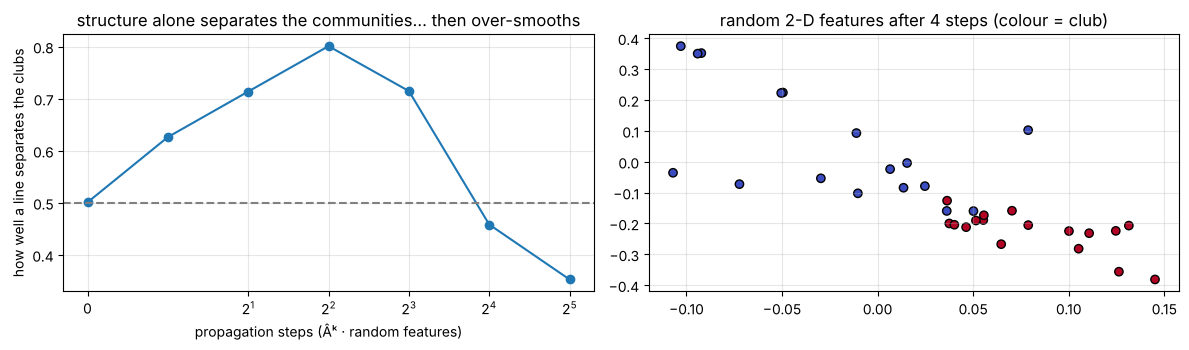

In [6]:
def normalised_adjacency(A):
    A_t = A + np.eye(len(A)); d = A_t.sum(1)
    return A_t / np.sqrt(np.outer(d, d))                       # D̃^-1/2 Ã D̃^-1/2

# Even WITHOUT training, propagating random features through the graph separates the communities:
A_hat = normalised_adjacency(A)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
steps = [0, 1, 2, 4, 8, 16, 32]
sep = np.array([[cross_val_score(LogisticRegression(), np.linalg.matrix_power(A_hat, k) @ np.random.default_rng(seed).normal(size=(34, 2)),
                                 club, cv=5).mean() for k in steps] for seed in range(20)])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(steps, sep.mean(0), "o-"); ax[0].set_xscale("symlog", base=2); ax[0].axhline(0.5, ls="--", c="gray")
ax[0].set_xlabel("propagation steps (Âᵏ · random features)"); ax[0].set_ylabel("how well a line separates the clubs")
ax[0].set_title("structure alone separates the communities… then over-smooths")
H4 = np.linalg.matrix_power(A_hat, 4) @ np.random.default_rng(1).normal(size=(34, 2))
ax[1].scatter(*H4.T, c=club, cmap="coolwarm", edgecolor="k"); ax[1].set_title("random 2-D features after 4 steps (colour = club)")
plt.tight_layout(); plt.show()

Each step averages a node's vector with its neighbours'. Members of the same community share many neighbours, so their vectors drift together, and **structure alone** makes the two clubs separable (about 80% after around 4 steps, starting from pure noise). Keep going and *everyone's* vectors converge to the same thing: separability falls back to chance. This is **over-smoothing**, which we'll meet again in Section 5. Training adds learned weights to make the propagation useful for the task.

## 4. A GCN for semi-supervised node classification

We need a bigger graph with **node features**. We generate a "citation network": 600 papers in 4 topics. Each paper has a 50-dimensional bag-of-words-like feature vector that is only **weakly** informative about its topic (lots of noise), and papers mostly cite papers on the same topic (**homophily**). We train with labels for only **20 papers per topic** — 80 of 600 — the typical semi-supervised setting (labelling is expensive; the graph is free).

In [7]:
def make_citation_graph(n_per=150, n_classes=4, d=50, p_in=0.04, p_out=0.004, signal=0.35, seed=0):
    r = np.random.default_rng(seed); n = n_per * n_classes
    y = np.repeat(np.arange(n_classes), n_per)
    centres = r.normal(0, 1, (n_classes, d))
    X = signal * centres[y] + r.normal(0, 1, (n, d))                    # weak, noisy features
    P = np.where(y[:, None] == y[None, :], p_in, p_out)
    A = (r.random((n, n)) < P).astype(float); A = np.triu(A, 1); A = A + A.T   # undirected, no self-loops
    return A, X.astype(np.float32), y

A_c, X_c, y_c = make_citation_graph()
n = len(y_c)
homophily = np.mean([y_c[i] == y_c[j] for i, j in zip(*np.nonzero(np.triu(A_c)))])
print(f"{n} nodes, {int(A_c.sum() / 2)} edges, average degree {A_c.sum(1).mean():.1f}, edge homophily {homophily:.0%}")

train_idx = np.concatenate([rng.choice(np.where(y_c == c)[0], 20, replace=False) for c in range(4)])
rest = rng.permutation(np.setdiff1d(np.arange(n), train_idx)); val_idx, test_idx = rest[:100], rest[100:]   # shuffle before splitting!
print(f"labelled for training: {len(train_idx)} nodes ({len(train_idx) / n:.0%}); test on {len(test_idx)}")

600 nodes, 2346 edges, average degree 7.8, edge homophily 76%
labelled for training: 80 nodes (13%); test on 420


In [8]:
# 📦 GCN in PyTorch, written from the formula (dense Â is fine for a few thousand nodes)
class GCN(nn.Module):
    def __init__(self, d_in, d_hidden, n_classes, n_layers=2, dropout=0.5):
        super().__init__()
        dims = [d_in] + [d_hidden] * (n_layers - 1) + [n_classes]
        self.layers = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims, dims[1:])])
        self.dropout = dropout
    def forward(self, X, A_hat, return_hidden=False):
        h = X
        for i, layer in enumerate(self.layers):
            h = F.dropout(h, self.dropout, self.training)
            h = A_hat @ layer(h)                         # transform with W, then aggregate over neighbours
            if i < len(self.layers) - 1:
                h = F.relu(h); hidden = h
        return (h, hidden) if return_hidden else h

class MLP(nn.Module):                                    # same model, but ignoring the graph (Â = I)
    def __init__(self, d_in, d_hidden, n_classes):
        super().__init__(); self.net = nn.Sequential(nn.Dropout(0.5), nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Dropout(0.5), nn.Linear(d_hidden, n_classes))
    def forward(self, X, A_hat=None): return self.net(X)

def train_node_classifier(model, X, A_hat, y, epochs=200, lr=0.01, wd=5e-4):
    X_t, y_t = torch.tensor(X), torch.tensor(y); A_t = torch.tensor(A_hat, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd); best_val, best_state = 0, None
    for _ in range(epochs):
        model.train(); out = model(X_t, A_t)
        loss = F.cross_entropy(out[train_idx], y_t[train_idx])          # loss ONLY on the 80 labelled nodes
        opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad(): pred = model(X_t, A_t).argmax(1).numpy()
        val = np.mean(pred[val_idx] == y[val_idx])
        if val >= best_val: best_val, best_state = val, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): pred = model(X_t, A_t).argmax(1).numpy()
    return np.mean(pred[test_idx] == y[test_idx])

A_hat_c = normalised_adjacency(A_c)
torch.manual_seed(0)
acc_mlp = train_node_classifier(MLP(50, 32, 4), X_c, A_hat_c, y_c)
acc_gcn = train_node_classifier(GCN(50, 32, 4), X_c, A_hat_c, y_c)
lp = label_propagation_python([list(np.nonzero(A_c[v])[0]) for v in range(n)], {int(v): int(y_c[v]) for v in train_idx}, 4)
acc_lp = np.mean(np.array(lp)[test_idx] == y_c[test_idx])
from sklearn.linear_model import LogisticRegression
acc_lr = LogisticRegression(max_iter=2000).fit(X_c[train_idx], y_c[train_idx]).score(X_c[test_idx], y_c[test_idx])
print(f"features only — logistic regression: {acc_lr:.3f} | MLP: {acc_mlp:.3f}")
print(f"graph only    — label propagation:   {acc_lp:.3f}")
print(f"features + graph — GCN:               {acc_gcn:.3f}")

features only — logistic regression: 0.764 | MLP: 0.790
graph only    — label propagation:   0.900
features + graph — GCN:               0.986


Features alone are too noisy; the graph alone is decent; **the GCN combines both** and wins clearly. Each node effectively averages its noisy features with its (mostly same-topic) neighbours' — denoising them.

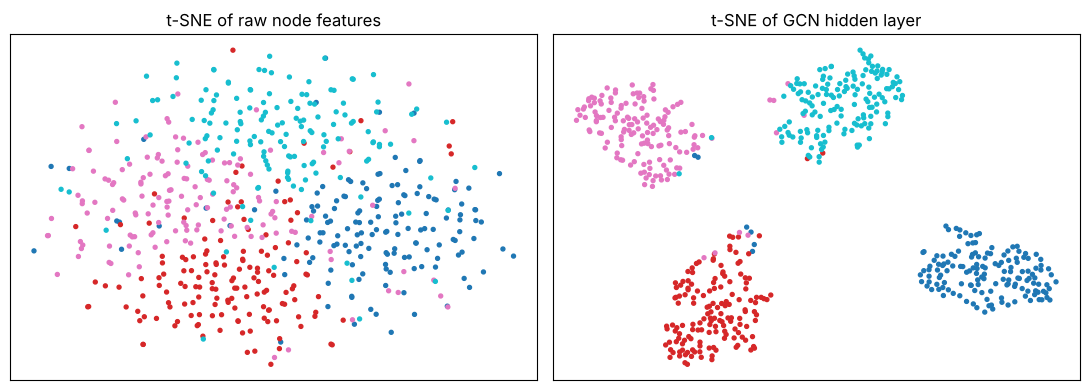

In [9]:
from sklearn.manifold import TSNE
torch.manual_seed(0); gcn = GCN(50, 32, 4); train_node_classifier(gcn, X_c, A_hat_c, y_c)
with torch.no_grad(): _, hidden = gcn(torch.tensor(X_c), torch.tensor(A_hat_c, dtype=torch.float32), return_hidden=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (Z, t) in zip(ax, [(X_c, "raw node features"), (hidden.numpy(), "GCN hidden layer")]):
    E2 = TSNE(2, random_state=0, init="pca").fit_transform(Z)
    a.scatter(*E2.T, c=y_c, cmap="tab10", s=8); a.set_title(f"t-SNE of {t}"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 5. When GNNs help — and when they don't

### Homophily vs heterophily
GCN-style averaging assumes **neighbours are similar** (homophily). In **heterophilous** graphs — where edges mostly connect *different* kinds of nodes (e.g. buyers↔sellers, some fraud rings, protein interactions, dating networks) — averaging mixes in the wrong signal.

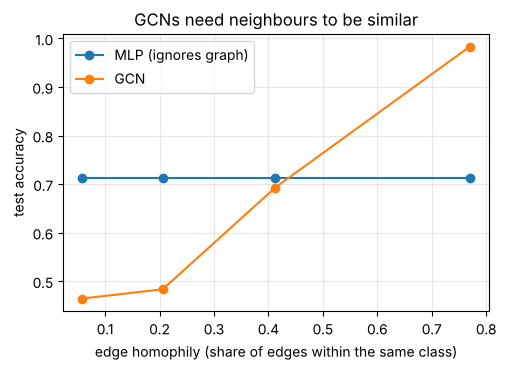

In [10]:
rows = []
for p_in, p_out in [(0.04, 0.004), (0.02, 0.01), (0.01, 0.013), (0.004, 0.02)]:
    A_h, X_h, y_h = make_citation_graph(p_in=p_in, p_out=p_out, seed=1)
    h = np.mean([y_h[i] == y_h[j] for i, j in zip(*np.nonzero(np.triu(A_h)))])
    torch.manual_seed(0); a_mlp = train_node_classifier(MLP(50, 32, 4), X_h, normalised_adjacency(A_h), y_h)
    torch.manual_seed(0); a_gcn = train_node_classifier(GCN(50, 32, 4), X_h, normalised_adjacency(A_h), y_h)
    rows.append((h, a_mlp, a_gcn))
rows = np.array(rows)
plt.plot(rows[:, 0], rows[:, 1], "o-", label="MLP (ignores graph)"); plt.plot(rows[:, 0], rows[:, 2], "o-", label="GCN")
plt.xlabel("edge homophily (share of edges within the same class)"); plt.ylabel("test accuracy"); plt.legend()
plt.title("GCNs need neighbours to be similar"); plt.show()

With high homophily the GCN is far better; as edges increasingly connect *different* classes, it falls **below** the plain MLP. Remedies: keep the node's own features separate from the neighbour aggregate (GraphSAGE-style concatenation), attention over neighbours (GAT), or heterophily-aware architectures. **Always compare against a graph-free baseline.**

### Over-smoothing
Each layer averages over neighbours. Stack too many and every node's representation converges to nearly the same vector — the graph version of "blurring until everything is grey". That's why most GNNs use only 2–4 layers (unlike CNNs with 100+).

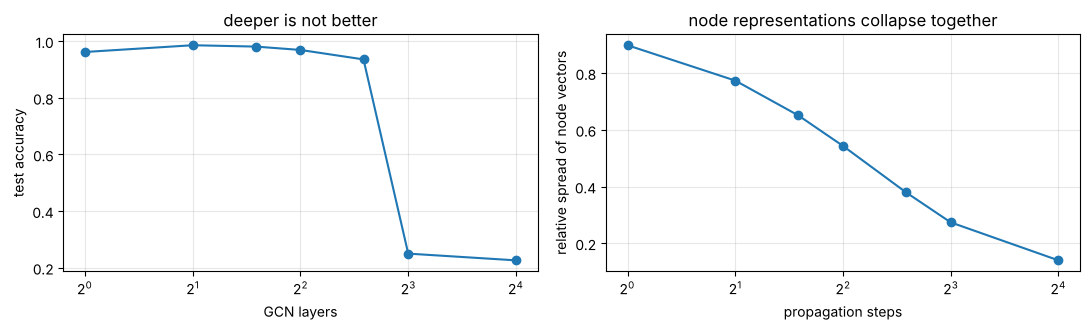

In [11]:
depth_acc, spread = [], []
for L_ in [1, 2, 3, 4, 6, 8, 16]:
    torch.manual_seed(0); depth_acc.append(train_node_classifier(GCN(50, 32, 4, n_layers=L_, dropout=0.2), X_c, A_hat_c, y_c))
    Hs = np.linalg.matrix_power(A_hat_c, L_) @ X_c                        # pure propagation, no weights
    spread.append(np.mean(np.linalg.norm(Hs - Hs.mean(0), axis=1)) / np.mean(np.linalg.norm(Hs, axis=1)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot([1, 2, 3, 4, 6, 8, 16], depth_acc, "o-"); ax[0].set_xlabel("GCN layers"); ax[0].set_ylabel("test accuracy"); ax[0].set_xscale("log", base=2)
ax[1].plot([1, 2, 3, 4, 6, 8, 16], spread, "o-"); ax[1].set_xlabel("propagation steps"); ax[1].set_ylabel("relative spread of node vectors"); ax[1].set_xscale("log", base=2)
ax[0].set_title("deeper is not better"); ax[1].set_title("node representations collapse together")
plt.tight_layout(); plt.show()

## 6. Other graph tasks

### 6.1 Link prediction — "will these two nodes connect?"
Friend suggestions, product recommendations (users and items form a bipartite graph — notebook 19), drug–target interactions, knowledge-graph completion.

Recipe: hide some edges; train a GNN **encoder** to produce node embeddings from the remaining graph; score a pair by the **dot product** of their embeddings; train with real edges as positives and random non-edges as negatives. Evaluate AUC on the hidden edges vs random non-edges. Compare against a classic heuristic: **common neighbours** (people with many mutual friends tend to become friends).

In [12]:
edges = np.array(np.nonzero(np.triu(A_c))).T
perm = rng.permutation(len(edges)); n_test = len(edges) // 10
test_edges, train_edges = edges[perm[:n_test]], edges[perm[n_test:]]
A_train = np.zeros_like(A_c); A_train[train_edges[:, 0], train_edges[:, 1]] = 1; A_train += A_train.T
def sample_non_edges(k, seed):
    r = np.random.default_rng(seed); out = []
    while len(out) < k:
        i, j = r.integers(0, n, 2)
        if i != j and A_c[i, j] == 0: out.append((i, j))
    return np.array(out)
test_neg = sample_non_edges(n_test, 1)

class GCNEncoder(nn.Module):
    def __init__(self, d_in, d_hidden=64, d_out=32):
        super().__init__(); self.l1, self.l2 = nn.Linear(d_in, d_hidden), nn.Linear(d_hidden, d_out)
    def forward(self, X, A_hat): return A_hat @ self.l2(F.relu(A_hat @ self.l1(X)))

torch.manual_seed(0)
enc = GCNEncoder(50); opt = torch.optim.Adam(enc.parameters(), lr=0.005, weight_decay=5e-4)
Xt, At = torch.tensor(X_c), torch.tensor(normalised_adjacency(A_train), dtype=torch.float32)
pos = torch.tensor(train_edges)
for epoch in range(300):
    enc.train(); Z = enc(F.dropout(Xt, 0.2), At); neg = torch.tensor(sample_non_edges(len(pos), 100 + epoch))   # fresh negatives each epoch
    score = lambda e: (Z[e[:, 0]] * Z[e[:, 1]]).sum(-1)
    loss = F.binary_cross_entropy_with_logits(torch.cat([score(pos), score(neg)]), torch.cat([torch.ones(len(pos)), torch.zeros(len(neg))]))
    opt.zero_grad(); loss.backward(); opt.step()

from sklearn.metrics import roc_auc_score
with torch.no_grad(): Z = enc(Xt, At).numpy()
labels_lp = np.r_[np.ones(n_test), np.zeros(n_test)]; pairs = np.vstack([test_edges, test_neg])
gnn_scores = (Z[pairs[:, 0]] * Z[pairs[:, 1]]).sum(1)
common_nb = (A_train @ A_train)[pairs[:, 0], pairs[:, 1]]                       # number of shared neighbours
feat_sim = (X_c[pairs[:, 0]] * X_c[pairs[:, 1]]).sum(1)
print(f"link prediction AUC on held-out edges — feature similarity: {roc_auc_score(labels_lp, feat_sim):.3f} | "
      f"common neighbours: {roc_auc_score(labels_lp, common_nb):.3f} | GCN encoder: {roc_auc_score(labels_lp, gnn_scores):.3f}")
oracle = (y_c[pairs[:, 0]] == y_c[pairs[:, 1]]).astype(float)
print(f"ceiling — a cheat that KNOWS every node's true topic and predicts 'same topic → linked': {roc_auc_score(labels_lp, oracle):.3f}")

link prediction AUC on held-out edges — feature similarity: 0.534 | common neighbours: 0.532 | GCN encoder: 0.678
ceiling — a cheat that KNOWS every node's true topic and predicts 'same topic → linked': 0.748


Read these numbers against the **ceiling**. In our generated graph, edges are drawn *at random within each topic*. So the best possible signal is "same topic → more likely linked", and even perfect knowledge of every topic only reaches an AUC of about 0.75 (printed above).
- **Feature similarity** fails, because the features are too noisy.
- **Common neighbours** fails, because the graph is sparse (average degree 8), so most true pairs share no friends yet.
- **The GCN** combines both sources and recovers a good part of the achievable signal.

On real social or citation graphs, where friends-of-friends really do become friends, common neighbours is a strong baseline. Always include it.

### 6.2 Graph classification — a label for a whole graph
Is this molecule toxic? Is this program malicious? Run message passing, then **pool** all node vectors into one graph vector (mean, sum or max — a "readout"), then classify.

Toy task: tell graphs with **two communities** apart from **random graphs** that have exactly the same number of edges.

In [13]:
def make_graph(two_communities, seed, with_clustering):
    n_ = 30
    sbm = nx.stochastic_block_model([15, 15], [[0.35, 0.03], [0.03, 0.35]], seed=int(seed))
    g = sbm if two_communities else nx.gnm_random_graph(n_, sbm.number_of_edges(), seed=int(seed))   # same edge count
    A_ = nx.to_numpy_array(g, nodelist=range(n_))
    X_ = A_.sum(1, keepdims=True) / 10                                                        # node feature: degree
    if with_clustering:                                                                       # + local clustering coefficient
        X_ = np.hstack([X_, [[nx.clustering(g, v)] for v in range(n_)]])
    return normalised_adjacency(A_).astype(np.float32), X_.astype(np.float32)

class GraphClassifier(nn.Module):
    def __init__(self, d_in, d=32):
        super().__init__(); self.l1, self.l2 = nn.Linear(d_in, d), nn.Linear(d, d); self.head = nn.Linear(d, 2)
    def forward(self, A_hat, X):
        h = F.relu(A_hat @ self.l1(X)); h = F.relu(A_hat @ self.l2(h))
        return self.head(h.mean(0))                                             # readout: mean over all nodes

g_labels = np.array([i % 2 == 0 for i in range(400)], int); tr, te = range(300), range(300, 400)
for with_cl in [False, True]:
    graphs = [make_graph(i % 2 == 0, i, with_cl) for i in range(400)]
    torch.manual_seed(0); gc = GraphClassifier(graphs[0][1].shape[1]); opt = torch.optim.Adam(gc.parameters(), lr=0.005)
    for epoch in range(30):
        for i in np.random.default_rng(epoch).permutation(list(tr)):
            A_i, X_i = map(torch.tensor, graphs[i])
            loss = F.cross_entropy(gc(A_i, X_i)[None], torch.tensor([g_labels[i]])); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        acc = np.mean([gc(*map(torch.tensor, graphs[i])).argmax().item() == g_labels[i] for i in te])
    print(f"GNN, node features = {'degree + clustering coefficient' if with_cl else 'degree only':32s} → test accuracy {acc:.2f}")

GNN, node features = degree only                      → test accuracy 0.50


GNN, node features = degree + clustering coefficient  → test accuracy 0.97


With only degree as the input, the GNN is at **chance**. That's not a training failure. It's a known **expressiveness limit**: standard message passing can't distinguish graphs that the Weisfeiler–Lehman (1-WL) test can't tell apart, and it can't count triangles. These two graph types have the same number of edges and very similar degrees. Their difference — dense, triangle-rich communities — is precisely what message passing over degrees can't see.

Adding one structural feature, each node's **clustering coefficient** (the share of its neighbours that are connected to each other), makes the task easy. Common remedies in practice are structural or positional features (cycle counts, random-walk or Laplacian encodings), random node features, or more expressive "higher-order" GNNs.

## 7. The GNN family and where they're used

| Model | Aggregation idea |
|---|---|
| **GCN** | symmetric-normalised average of neighbours (incl. self) |
| **GraphSAGE** | sample a fixed number of neighbours; concatenate self with aggregate → scales to huge graphs, works on unseen nodes (*inductive*) |
| **GAT** | **attention** weights per neighbour (notebook 16) — learn which neighbours matter |
| **GIN** | sum aggregation + MLP — provably as expressive as the Weisfeiler-Lehman graph-isomorphism test |
| **Graph transformers** | attention over all nodes, with structural positional encodings |

**Libraries:** PyTorch Geometric (PyG) and DGL provide these layers with efficient **sparse** message passing, neighbour sampling for graphs with billions of edges, and standard datasets (Cora, PubMed, OGB).

**Applications:** recommendation (Pinterest's PinSage, Uber Eats), fraud and anti-money-laundering, traffic and ETA prediction (Google Maps), molecule property prediction and drug discovery, protein structure (AlphaFold uses graph-like attention over residues), chip design, physics simulation, and knowledge graphs.

## Key takeaways
- A graph = nodes + edges; adjacency matrix A; classic features (degree, PageRank, clustering) still make strong baselines.
- Message passing: each node aggregates its neighbours' vectors, then transforms — in matrix form $\hat A H W$.
- k layers = k-hop receptive field. Few labels + a homophilous graph → GNNs shine (semi-supervised learning).
- GNNs can hurt on heterophilous graphs; deep GNNs over-smooth — compare against graph-free baselines and keep them shallow.
- Tasks: node classification, link prediction (dot-product decoder), graph classification (pooling readout).

## Exercises
1. Implement a **GraphSAGE-style** layer: $h_v' = \sigma(W[h_v \,\|\, \text{mean}_{u \in N(v)} h_u])$ (concatenate self and neighbour mean). Does it do better than GCN on the heterophilous graphs?
2. Replace the GCN's normalised adjacency with a simple row-normalised one ($\tilde D^{-1}\tilde A$). Any difference?
3. Use the karate club with only nodes 0 and 33 labelled, node features = one-hot identity, and train a 2-layer GCN. Compare with label propagation.
4. In link prediction, add the common-neighbours count as an extra input to the scoring function. Does AUC improve?

In [14]:
# Exercise 1 — solution
class SAGE(nn.Module):
    def __init__(self, d_in, d_hidden, n_classes):
        super().__init__(); self.l1 = nn.Linear(2 * d_in, d_hidden); self.l2 = nn.Linear(2 * d_hidden, n_classes)
    def forward(self, X, A_hat):
        A_mean = (A_hat > 0).float(); A_mean = A_mean / A_mean.sum(1, keepdim=True).clamp(min=1)
        h = F.relu(self.l1(F.dropout(torch.cat([X, A_mean @ X], 1), 0.5, self.training)))
        return self.l2(torch.cat([h, A_mean @ h], 1))
A_het, X_het, y_het = make_citation_graph(p_in=0.004, p_out=0.02, seed=1)
for name, M in [("MLP", MLP(50, 32, 4)), ("GCN", GCN(50, 32, 4)), ("GraphSAGE-style", SAGE(50, 32, 4))]:
    torch.manual_seed(0); print(f"heterophilous graph — {name:16s} test acc {train_node_classifier(M, X_het, normalised_adjacency(A_het), y_het):.3f}")
print("(chance = 0.25.) Averaging neighbours that mostly belong to OTHER classes drowns the node's own signal;")
print("keeping the node's own features separate from the neighbour average (GraphSAGE-style) recovers it.")

heterophilous graph — MLP              test acc 0.738


heterophilous graph — GCN              test acc 0.467


heterophilous graph — GraphSAGE-style  test acc 0.771
(chance = 0.25.) Averaging neighbours that mostly belong to OTHER classes drowns the node's own signal;
keeping the node's own features separate from the neighbour average (GraphSAGE-style) recovers it.


**Next:** [21 · Generative Models](21_generative_models.ipynb) — autoencoders, VAEs, GANs and diffusion.

*Going deeper / interview prep:* `DL_Interview_Notes.md` §9.3 (embeddings), `ML_System_Design_Notes.md` §7.4 (fraud detection), §4.2 (two-tower retrieval) · `Linear_Algebra_Notes.md` Part 7 (eigenvectors, which underlie spectral graph methods and PageRank) · code: `ml_from_scratch_part2.py` → `SpectralClustering`.